# EDA — Segmentación de miotubos (`vt/`)

Análisis exploratorio inicial del dataset, siguiendo la **sección 4.1 (Auditoría inicial)** del documento del proyecto:

1. Inventario de archivos y correspondencia entre carpetas
2. Dimensiones, profundidad de bits, canales y rango de intensidades
3. Distribución de intensidades / iluminación entre imágenes
4. Máscaras: valores, máscaras vacías, % de píxeles de miotubo (desbalance)
5. Etiquetas YOLO: instancias por imagen, vértices, polígonos irregulares
6. Consistencia YOLO ↔ `masks_png` ↔ COCO
7. Morfología de instancias (área, elongación, solidez, traslapes)
8. Inspección visual (muestras, `verification/`, casos extremos)
9. Indicios de grupos / posibles duplicados (riesgo de *data leakage*)
10. Resumen y tablas exportadas

> Este notebook **no modifica** los datos originales. Solo lee y genera reportes en `eda_outputs/`.

> ### Resumen de hallazgos clave
> 1. **Las etiquetas son rectángulos rotados (siempre 4 vértices) que cubren tramos de miotubo**, no contornos completos, y muchos miotubos visibles no están anotados. La máscara semántica es una **anotación parcial / débil**.
> 2. **Hay imágenes duplicadas** con nombres distintos (117 pares casi idénticos). Si no se agrupan antes de la partición, habrá *data leakage*.
> 3. **Desbalance fuerte:** solo el 1.76 % de los píxeles son miotubo.
> 4. **Hay etiquetas defectuosas:** 2 cajas gigantes, 30 polígonos fuera de [0,1] y 34 máscaras vacías, algunas con miotubos visibles.
> 5. **Las imágenes son homogéneas:** 2592×1944, uint8, 1 canal, iluminación bastante uniforme.
>
> Detalle en las celdas **🔎 Observaciones** y en la tabla final de conclusiones.

## 0. Configuración y carga de datos

El notebook se ejecutó **localmente en VS Code**. En la celda siguiente, `DATA_PATH` apunta a la carpeta `vt` (o a `vt.zip`). El código localiza automáticamente la carpeta que contiene `images/`, `labels/`, `masks_png/`, etc.

In [3]:
# ====== CONFIGURA AQUÍ ======
# Puede ser la carpeta vt (aunque adentro tenga otra vt/) o un archivo vt.zip
DATA_PATH = r"C:\Users\dwigo\Documents\septimo_reto_2\vt"
# ============================

import os, zipfile
from pathlib import Path

DATA_PATH = Path(DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"No existe la ruta: {DATA_PATH}")

if DATA_PATH.suffix.lower() == ".zip":
    destino = DATA_PATH.with_suffix("")          # descomprime junto al zip
    if not destino.exists():
        with zipfile.ZipFile(DATA_PATH) as z:
            z.extractall(destino)
    BUSCAR_EN = destino
else:
    BUSCAR_EN = DATA_PATH

print("Buscando el dataset en:", BUSCAR_EN)

Buscando el dataset en: C:\Users\dwigo\Documents\septimo_reto_2\vt


In [4]:
import os, re, json, random, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
random.seed(SEED); np.random.seed(SEED)

def encontrar_raiz(base):
    # Busca la carpeta que contiene images/ y masks_png/ (o labels/)
    base = Path(base)
    for p in [base, *sorted(base.rglob("*"))]:
        if p.is_dir() and (p / "images").is_dir() and ((p / "masks_png").is_dir() or (p / "labels").is_dir()):
            return p
    raise FileNotFoundError(f"No encontré una carpeta con images/ y masks_png/ dentro de {base}")

ROOT = encontrar_raiz(BUSCAR_EN)
DIRS = {k: ROOT / k for k in ["images", "labels", "masks_png", "verification", "coco"]}
OUT = Path("/content/eda_outputs") if Path("/content").exists() else Path("eda_outputs")
OUT.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
for k, v in DIRS.items():
    print(f"  {k:13s} {'OK' if v.exists() else 'NO EXISTE'}  {v}")

ROOT: C:\Users\dwigo\Documents\septimo_reto_2\vt
  images        OK  C:\Users\dwigo\Documents\septimo_reto_2\vt\images
  labels        OK  C:\Users\dwigo\Documents\septimo_reto_2\vt\labels
  masks_png     OK  C:\Users\dwigo\Documents\septimo_reto_2\vt\masks_png
  verification  OK  C:\Users\dwigo\Documents\septimo_reto_2\vt\verification
  coco          OK  C:\Users\dwigo\Documents\septimo_reto_2\vt\coco


## 1. Inventario de archivos y correspondencia entre carpetas

In [5]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

def listar(d, exts=None):
    if not d.exists():
        return {}
    out = {}
    for p in sorted(d.rglob("*")):
        if p.is_file() and (exts is None or p.suffix.lower() in exts):
            out[p.stem] = p
    return out

img_files  = listar(DIRS["images"], IMG_EXT)
lbl_files  = listar(DIRS["labels"], {".txt"})
mask_files = listar(DIRS["masks_png"], IMG_EXT)
ver_files  = listar(DIRS["verification"], IMG_EXT)
coco_jsons = sorted(DIRS["coco"].rglob("*.json")) if DIRS["coco"].exists() else []

inv = pd.DataFrame({
    "carpeta": ["images", "labels", "masks_png", "verification", "coco (json)"],
    "n_archivos": [len(img_files), len(lbl_files), len(mask_files), len(ver_files), len(coco_jsons)],
})
display(inv)

# Extensiones por carpeta
for nombre, d in [("images", img_files), ("masks_png", mask_files), ("verification", ver_files)]:
    print(nombre, dict(Counter(p.suffix.lower() for p in d.values())))

# Otros archivos (p. ej. logs de conversión o listas de etiquetas irregulares)
extras = [p for p in ROOT.rglob("*") if p.is_file()
          and p.parent.name not in {"images", "labels", "masks_png", "verification"}
          and p.suffix.lower() != ".json"]
if extras:
    print("\nOtros archivos encontrados (revísalos, pueden documentar etiquetas irregulares):")
    for p in extras[:30]:
        print("  ", p.relative_to(ROOT))

,carpeta,n_archivos
0,images,306
1,labels,318
2,masks_png,306
3,verification,306
4,coco (json),1


images {'.png': 306}
masks_png {'.png': 306}
verification {'.png': 306}


In [6]:
# ¿Cada imagen tiene su etiqueta, máscara y overlay?
stems = set(img_files)
falta = {
    "imagen sin label .txt":       sorted(stems - set(lbl_files)),
    "imagen sin máscara png":      sorted(stems - set(mask_files)),
    "imagen sin verification":     sorted(stems - set(ver_files)),
    "label sin imagen":            sorted(set(lbl_files) - stems),
    "máscara sin imagen":          sorted(set(mask_files) - stems),
}
for k, v in falta.items():
    print(f"{k:28s}: {len(v):4d}   {v[:5]}{' ...' if len(v) > 5 else ''}")

# Si verification usa otro sufijo en el nombre (p.ej. '_overlay'), intenta emparejar por prefijo
if len(falta["imagen sin verification"]) == len(stems) and ver_files:
    print("\nNingún overlay coincide por nombre exacto. Ejemplos de nombres en verification/:",
          list(ver_files)[:5])

STEMS = sorted(stems)
print("\nImágenes a analizar:", len(STEMS))

imagen sin label .txt       :    0   []
imagen sin máscara png      :    0   []
imagen sin verification     :    0   []
label sin imagen            :   12   ['1841443f-4b2b8615-75d4-4b2e-bccd-5731cc9b8ffc_A2_02_03_Best (1)', '2f239cb7-4b2b8615-75d4-4b2e-bccd-5731cc9b8ffc_A2_01_04_Best (1)', '30756772-35f892c1-da41-4a26-afbf-cb846cdf7436_A3_05_05_Best (1)', '5c9ac81f-6a55a585-2551-49dd-be42-a9371d0c40ea_A2_01_04_Best (1)', '69ee7dca-195893df-aa40-4944-8592-2fa62f94d608_B2_01_05_Best (1)'] ...
máscara sin imagen          :    0   []

Imágenes a analizar: 306


### 🔎 Observaciones — Inventario
- Hay **306 imágenes**, cada una con su máscara PNG, su overlay de `verification/` y su `.txt`. No falta ningún archivo.
- `labels/` tiene **318** archivos: **12 etiquetas no tienen imagen**. Todas terminan en `" (1)"`, lo que indica copias duplicadas (por ejemplo, de una descarga repetida). Se ignoran en el análisis. Conviene revisar si son idénticas a su original y, si lo son, sacarlas de la carpeta de trabajo (sin borrar el original).
- Hay un solo `annotations.json` de COCO.
- Hay dos convenciones de nombre:
  - **254 imágenes** del tipo `<hash8>-<UUID>_<pozo>_<f>_<c>_Best`, por ejemplo `..._A3_04_03_Best`.
  - **51–52 imágenes** del tipo `<hash8>-cellNN`.

  Pueden ser dos fuentes o dos protocolos de adquisición distintos.

## 2. Propiedades de las imágenes: dimensiones, bits, canales, rango de intensidad

In [7]:
def leer(path):
    # Lee sin alterar profundidad de bits ni canales
    arr = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if arr is None:                      # fallback (p.ej. algunos TIFF)
        arr = np.array(Image.open(path))
    if arr.ndim == 3 and arr.shape[2] >= 3:
        arr = arr[..., ::-1] if arr.shape[2] == 3 else arr[..., [2, 1, 0, 3]]  # BGR(A)->RGB(A)
    return arr

def a_gris(arr):
    if arr.ndim == 2:
        return arr
    return arr[..., :3].mean(axis=2).astype(arr.dtype)

filas = []
for s in tqdm(STEMS, desc="imágenes"):
    p = img_files[s]
    a = leer(p)
    pil = Image.open(p)
    ch = 1 if a.ndim == 2 else a.shape[2]
    canales_iguales = None
    if ch >= 3:
        canales_iguales = bool(np.array_equal(a[..., 0], a[..., 1]) and np.array_equal(a[..., 1], a[..., 2]))
    g = a_gris(a).astype(np.float64)
    filas.append(dict(
        stem=s, ext=p.suffix.lower(), modo_pil=pil.mode, dtype=str(a.dtype),
        alto=a.shape[0], ancho=a.shape[1], canales=ch, rgb_es_gris=canales_iguales,
        kb=p.stat().st_size / 1024,
        min=g.min(), max=g.max(), media=g.mean(), std=g.std(),
        p1=np.percentile(g, 1), p50=np.percentile(g, 50), p99=np.percentile(g, 99),
        frac_saturado=float((g >= np.iinfo(a.dtype).max).mean()) if np.issubdtype(a.dtype, np.integer) else np.nan,
        frac_cero=float((g == 0).mean()),
    ))
df_img = pd.DataFrame(filas).set_index("stem")

print("Resoluciones (alto x ancho):")
display(df_img.groupby(["alto", "ancho"]).size().rename("n").sort_values(ascending=False).to_frame())
print("dtype / modo / canales:")
display(df_img.groupby(["dtype", "modo_pil", "canales", "rgb_es_gris"], dropna=False).size().rename("n").to_frame())
display(df_img[["min", "max", "media", "std", "p1", "p50", "p99", "frac_saturado", "frac_cero", "kb"]].describe().T.round(3))

imágenes:   0%|          | 0/306 [00:00<?, ?it/s]

Resoluciones (alto x ancho):


,,n
alto,ancho,
1944,2592,306


dtype / modo / canales:


,,,,n
dtype,modo_pil,canales,rgb_es_gris,
uint8,L,1,NaN,306


,count,mean,std,min,25%,50%,75%,max
min,306.0,11.095,5.493,0.000,7.250,11.000,14.000,26.000
max,306.0,255.000,0.000,255.000,255.000,255.000,255.000,255.000
media,306.0,152.564,8.185,98.550,151.148,154.321,156.523,165.361
std,306.0,34.590,5.183,26.625,31.331,33.198,35.769,60.959
p1,306.0,57.513,18.663,3.000,51.250,62.000,69.000,91.000
p50,306.0,153.376,6.619,116.000,151.000,155.000,157.000,166.000
p99,306.0,228.252,8.654,200.000,224.000,227.000,232.000,255.000
frac_saturado,306.0,0.001,0.002,0.000,0.000,0.000,0.001,0.013
frac_cero,306.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
kb,306.0,4129.742,175.559,3521.143,4109.473,4190.172,4239.781,4366.341


**Qué revisar:**
- Si hay varias resoluciones → habrá que decidir *resize* vs. parches (sección 4.6).
- Si las imágenes son RGB pero `rgb_es_gris=True` → en realidad son escala de grises guardadas en 3 canales; puedes usar 1 canal.
- `dtype` uint16 vs uint8 → define cómo normalizar.
- `frac_saturado` alto → pérdida de información en zonas brillantes.

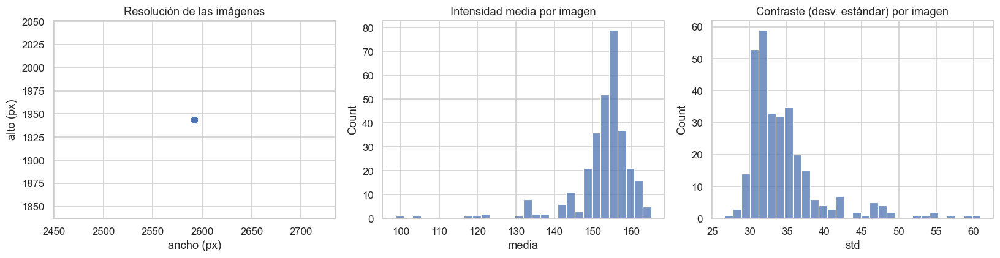

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(df_img["ancho"], df_img["alto"], alpha=.6)
axes[0].set(title="Resolución de las imágenes", xlabel="ancho (px)", ylabel="alto (px)")
sns.histplot(df_img["media"], bins=30, ax=axes[1]); axes[1].set(title="Intensidad media por imagen")
sns.histplot(df_img["std"], bins=30, ax=axes[2]); axes[2].set(title="Contraste (desv. estándar) por imagen")
plt.tight_layout(); plt.savefig(OUT / "02_propiedades.png", bbox_inches="tight"); plt.show()

### 🔎 Observaciones — Propiedades de las imágenes
- **Todas las imágenes miden 2592 × 1944 px** (una sola resolución), así que no hay que homologar tamaños.
- **Todas son `uint8`, modo `L`, 1 canal**: escala de grises real, no RGB. Se puede usar un modelo de 1 canal de entrada.
- La **intensidad media es muy estable** entre imágenes (≈ 152 ± 8). La desviación estándar (contraste) es ≈ 35 ± 5, con algunas imágenes más contrastadas (máx. 61).
- La saturación es despreciable (0.1 % de píxeles en 255 en promedio, máx. 1.3 %) y no hay píxeles en 0. Hay poca pérdida de información en los extremos.
- Archivos de ~4 MB cada uno. Cargar las 306 imágenes completas en RAM ocupa ≈ 1.5 GB en uint8. Es manejable, pero en float32 se cuadruplica (~6 GB), así que conviene cargar por lotes o en parches.

## 3. Distribución de intensidades e iluminación

histogramas:   0%|          | 0/306 [00:00<?, ?it/s]

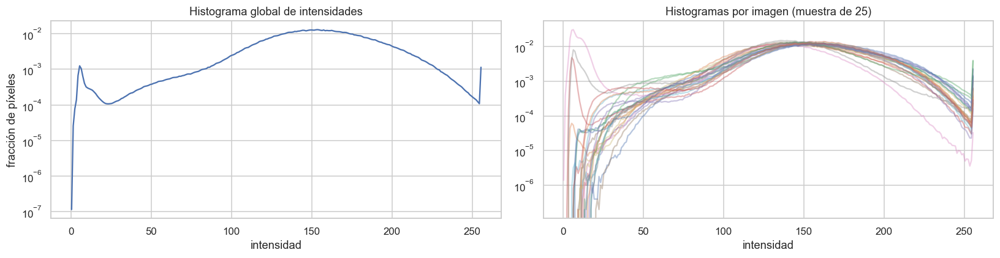

In [9]:
# Histograma global (submuestreo de píxeles para no saturar memoria)
max_val = 65535 if (df_img["dtype"] == "uint16").any() else 255
n_bins = 256
hist_global = np.zeros(n_bins)
hist_por_img = {}
for s in tqdm(STEMS, desc="histogramas"):
    g = a_gris(leer(img_files[s])).ravel()
    h, edges = np.histogram(g, bins=n_bins, range=(0, max_val + 1))
    hist_global += h
    hist_por_img[s] = h / h.sum()

centros = (edges[:-1] + edges[1:]) / 2
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(centros, hist_global / hist_global.sum())
axes[0].set(title="Histograma global de intensidades", xlabel="intensidad", ylabel="fracción de píxeles", yscale="log")

# Curvas por imagen: muestra la variabilidad de iluminación entre imágenes
for s in random.sample(STEMS, min(25, len(STEMS))):
    axes[1].plot(centros, hist_por_img[s], alpha=.4)
axes[1].set(title="Histogramas por imagen (muestra de 25)", xlabel="intensidad", yscale="log")
plt.tight_layout(); plt.savefig(OUT / "03_histogramas.png", bbox_inches="tight"); plt.show()

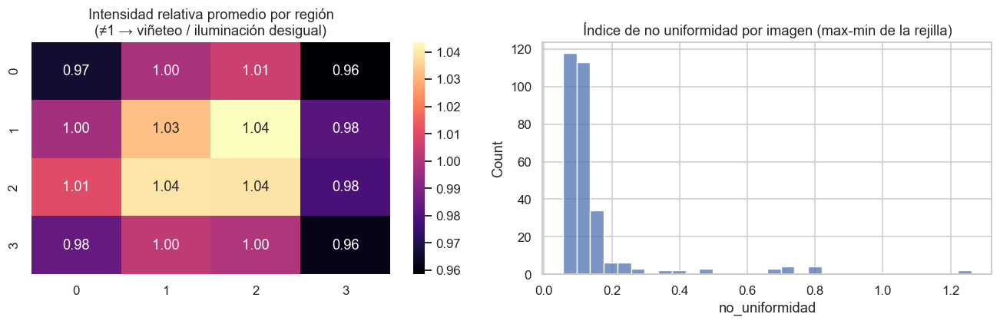

In [10]:
# Iluminación no uniforme: compara la media de intensidad en una rejilla 4x4 de cada imagen
def perfil_iluminacion(g, k=4):
    h, w = g.shape
    return np.array([[g[i*h//k:(i+1)*h//k, j*w//k:(j+1)*w//k].mean() for j in range(k)] for i in range(k)])

perfiles = []
for s in STEMS:
    g = a_gris(leer(img_files[s])).astype(np.float32)
    p = perfil_iluminacion(g)
    perfiles.append(p / (g.mean() + 1e-6))
perfil_medio = np.mean(perfiles, axis=0)
df_img["no_uniformidad"] = [float(p.max() - p.min()) for p in perfiles]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(perfil_medio, annot=True, fmt=".2f", cmap="magma", ax=axes[0])
axes[0].set_title("Intensidad relativa promedio por región\n(≠1 → viñeteo / iluminación desigual)")
sns.histplot(df_img["no_uniformidad"], bins=30, ax=axes[1])
axes[1].set_title("Índice de no uniformidad por imagen (max-min de la rejilla)")
plt.tight_layout(); plt.savefig(OUT / "03_iluminacion.png", bbox_inches="tight"); plt.show()

### 🔎 Observaciones — Intensidades e iluminación
- El histograma es **unimodal, centrado en ~150**, con una cola hacia la izquierda (los miotubos y los restos celulares son **más oscuros que el fondo**).
- El **pico pequeño cerca de 5** y el pico en 255 vienen de unas pocas imágenes: corresponden al **borde negro del pozo** (visible en la imagen más oscura de la sección 8) y a reflejos saturados.
- **Viñeteo leve:** el centro es ~4 % más brillante y las esquinas ~4 % más oscuras. La columna derecha es sistemáticamente más oscura (0.96–0.98).
- El índice de no uniformidad es < 0.2 en la gran mayoría. **~20 imágenes tienen > 0.3**, sobre todo las que muestran el borde del pozo. Ese borde es un artefacto que el modelo podría confundir con estructura.
- **Implicación:** una normalización global (z-score con estadísticas de train) probablemente baste. Una corrección de fondo o CLAHE es candidata a experimento (pregunta guía 1), no un requisito.

## 4. Máscaras (`masks_png`): valores, máscaras vacías y desbalance de clases

In [11]:
filas = []
valores_globales = Counter()
for s in tqdm(STEMS, desc="máscaras"):
    if s not in mask_files:
        continue
    m = leer(mask_files[s])
    if m.ndim == 3:
        m = m[..., 0]
    vals, cnts = np.unique(m, return_counts=True)
    valores_globales.update(dict(zip(vals.tolist(), cnts.tolist())))
    fg = m > 0
    n_cc, _ = cv2.connectedComponents(fg.astype(np.uint8), connectivity=8)
    filas.append(dict(
        stem=s, m_alto=m.shape[0], m_ancho=m.shape[1], m_dtype=str(m.dtype),
        valores=tuple(vals.tolist()), frac_fg=float(fg.mean()),
        px_fg=int(fg.sum()), comp_conexas=n_cc - 1,
    ))
df_mask = pd.DataFrame(filas).set_index("stem")
df = df_img.join(df_mask, how="left")

print("Valores presentes en todas las máscaras:", dict(valores_globales))
print("Combinaciones de valores por máscara:", dict(Counter(df_mask["valores"])))
tam_distinto = df[(df["alto"] != df["m_alto"]) | (df["ancho"] != df["m_ancho"])].dropna(subset=["m_alto"])
print("Máscaras con tamaño distinto a su imagen:", len(tam_distinto), list(tam_distinto.index[:5]))
print(f"Máscaras vacías (0 px de miotubo): {(df_mask['frac_fg'] == 0).sum()} de {len(df_mask)}")

máscaras:   0%|          | 0/306 [00:00<?, ?it/s]

Valores presentes en todas las máscaras: {0: 1514758786, 1: 27128702}
Combinaciones de valores por máscara: {(0,): 34, (0, 1): 272}
Máscaras con tamaño distinto a su imagen: 0 []
Máscaras vacías (0 px de miotubo): 34 de 306


Píxeles de miotubo (global): 1.76%   fondo: 98.24%
Razón fondo:miotubo ≈ 55.8 : 1
pos_weight sugerido para BCE (fondo/miotubo): 55.84


,count,mean,std,min,25%,50%,75%,max
fracción de miotubo por imagen,306.0,0.0176,0.0529,0.0,0.0044,0.0086,0.017,0.7279


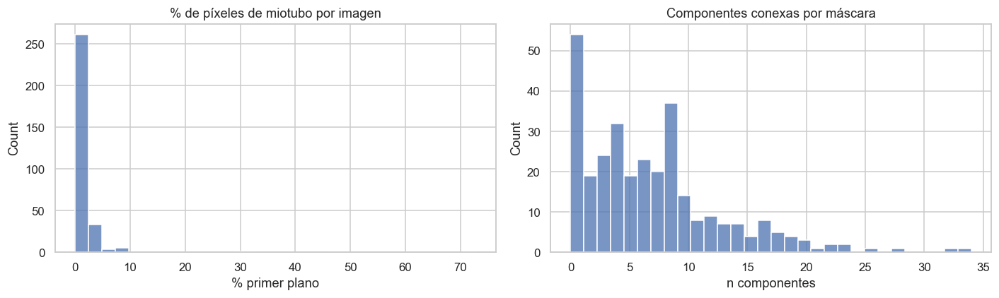

In [12]:
total_fg = df_mask["px_fg"].sum()
total_px = (df_mask["m_alto"] * df_mask["m_ancho"]).sum()
frac = total_fg / total_px
print(f"Píxeles de miotubo (global): {frac:.2%}   fondo: {1-frac:.2%}")
print(f"Razón fondo:miotubo ≈ {(1-frac)/max(frac,1e-9):.1f} : 1")
print(f"pos_weight sugerido para BCE (fondo/miotubo): {(1-frac)/max(frac,1e-9):.2f}")
display(df_mask["frac_fg"].describe().to_frame("fracción de miotubo por imagen").T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_mask["frac_fg"] * 100, bins=30, ax=axes[0])
axes[0].set(title="% de píxeles de miotubo por imagen", xlabel="% primer plano")
sns.histplot(df_mask["comp_conexas"], bins=30, ax=axes[1])
axes[1].set(title="Componentes conexas por máscara", xlabel="n componentes")
plt.tight_layout(); plt.savefig(OUT / "04_desbalance.png", bbox_inches="tight"); plt.show()

**Interpretación:** si el porcentaje de miotubo es bajo, la *accuracy* global será engañosa (un modelo que predice todo fondo tendría accuracy alta). Esto justifica usar **BCE + Dice** (o `pos_weight`) y reportar IoU/Dice, como pide la sección 4.5/4.8.

### 🔎 Observaciones — Máscaras y desbalance
- Las máscaras tienen exactamente los valores **{0, 1}** y el mismo tamaño que su imagen. El formato es correcto.
- **34 máscaras están vacías (11 %)** y coinciden con las 34 imágenes sin instancias YOLO. En la sección 8 se ve que **al menos algunas tienen miotubos claramente visibles** (por ejemplo `793786ab-...` y `8e735dd5-...`). Probablemente son imágenes **sin anotar**, no negativos reales.
- **Desbalance:** el 1.76 % de los píxeles son miotubo (≈ 56 : 1). La mediana por imagen es todavía menor (0.86 %). Un modelo que prediga "todo fondo" tendría ~98 % de *accuracy* e IoU = 0.
- La distribución tiene **cola larga**: el máximo es 72.8 %, pero esas cifras vienen de **cajas mal anotadas** (ver sección 5 y casos extremos). Sin esos atípicos, el % de miotubo por imagen rara vez pasa de ~5 %.
- **Implicación:** usar BCE + Dice (o Focal + Dice). El `pos_weight` de ~56 es una cota superior; empezar con 10–20 y ajustar en validación. Considerar **muestreo de parches sesgado a parches con miotubo**.

## 5. Etiquetas YOLO Segmentation (`labels/*.txt`)

In [13]:
def parse_yolo(path):
    # Devuelve lista de (clase, Nx2 array normalizado) y lista de problemas
    polys, problemas = [], []
    for i, linea in enumerate(path.read_text().strip().splitlines()):
        t = linea.split()
        if not t:
            continue
        try:
            cls = int(float(t[0])); coords = np.array(t[1:], dtype=float)
        except ValueError:
            problemas.append(f"línea {i}: no numérica"); continue
        if len(coords) % 2:
            problemas.append(f"línea {i}: número impar de coordenadas"); coords = coords[:-1]
        pts = coords.reshape(-1, 2)
        if len(pts) < 3:
            problemas.append(f"línea {i}: <3 vértices")
        if (pts < 0).any() or (pts > 1).any():
            problemas.append(f"línea {i}: coords fuera de [0,1]")
        polys.append((cls, pts))
    return polys, problemas

YOLO = {}
filas_inst, filas_prob = [], []
for s in tqdm(STEMS, desc="labels"):
    if s not in lbl_files:
        continue
    polys, probs = parse_yolo(lbl_files[s])
    YOLO[s] = polys
    H, W = int(df.loc[s, "alto"]), int(df.loc[s, "ancho"])
    for k, (cls, pts) in enumerate(polys):
        px = (pts * [W, H]).astype(np.float32)
        area = cv2.contourArea(px) if len(px) >= 3 else 0.0
        filas_inst.append(dict(stem=s, idx=k, clase=cls, n_vertices=len(pts), area_px=area))
    for p in probs:
        filas_prob.append(dict(stem=s, problema=p))

df_inst = pd.DataFrame(filas_inst)
df_prob = pd.DataFrame(filas_prob, columns=["stem", "problema"])
df["n_inst_yolo"] = pd.Series({s: len(p) for s, p in YOLO.items()})

print("Clases presentes:", dict(Counter(df_inst["clase"])) if len(df_inst) else {})
print("Total de instancias (polígonos):", len(df_inst))
print("Imágenes sin ninguna instancia:", int((df["n_inst_yolo"] == 0).sum()))
print("Polígonos con problemas de formato:", len(df_prob))
if len(df_prob):
    display(df_prob.head(20))
display(df["n_inst_yolo"].describe().to_frame("instancias por imagen").T)

labels:   0%|          | 0/306 [00:00<?, ?it/s]

Clases presentes: {0: 2148}
Total de instancias (polígonos): 2148
Imágenes sin ninguna instancia: 34
Polígonos con problemas de formato: 30


,stem,problema
0,0062917b-195893df-aa40-4944-8592-2fa62f94d608_...,"línea 21: coords fuera de [0,1]"
1,10f23e6d-cell32,"línea 5: coords fuera de [0,1]"
2,22d32863-cell12,"línea 24: coords fuera de [0,1]"
3,30fda19f-42d5b90b-a80c-4524-b17f-99018fff2a56_...,"línea 2: coords fuera de [0,1]"
4,3bdaa16d-195893df-aa40-4944-8592-2fa62f94d608_...,"línea 7: coords fuera de [0,1]"
5,3d26f913-fc183976-b90b-42f5-b0f5-3142ad00fae7_...,"línea 6: coords fuera de [0,1]"
6,445c8778-137a548c-ba26-40cc-bcac-d20d77cf6fd8_...,"línea 1: coords fuera de [0,1]"
7,53e71d47-fc183976-b90b-42f5-b0f5-3142ad00fae7_...,"línea 7: coords fuera de [0,1]"
8,53e71d47-fc183976-b90b-42f5-b0f5-3142ad00fae7_...,"línea 8: coords fuera de [0,1]"
9,54d4b99a-cell35,"línea 0: coords fuera de [0,1]"


,count,mean,std,min,25%,50%,75%,max
instancias por imagen,306.0,7.019608,5.95499,0.0,3.0,6.0,10.0,34.0


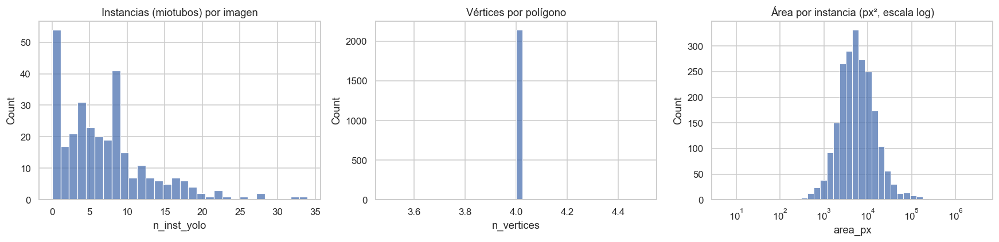

Polígonos sospechosos (área < 555 px² o <4 vértices): 22


,stem,idx,clase,n_vertices,area_px
490,312d4597-6a55a585-2551-49dd-be42-a9371d0c40ea_...,4,0,4,5.348114
1041,80225825-2ab5ac69-bc0f-4173-a326-cc1fecc40538_...,4,0,4,34.413983
132,10f23e6d-cell32,11,0,4,55.509549
843,6601420f-42d5b90b-a80c-4524-b17f-99018fff2a56_...,2,0,4,145.286948
153,140c6a4e-d64a7ec0-a77e-4eaa-8c1d-e4c6e7afdcf4_...,13,0,4,222.038780
161,140c6a4e-d64a7ec0-a77e-4eaa-8c1d-e4c6e7afdcf4_...,21,0,4,252.288691
1706,c9cd72fd-6a55a585-2551-49dd-be42-a9371d0c40ea_...,12,0,4,293.322909
144,140c6a4e-d64a7ec0-a77e-4eaa-8c1d-e4c6e7afdcf4_...,4,0,4,329.028003
169,140c6a4e-d64a7ec0-a77e-4eaa-8c1d-e4c6e7afdcf4_...,29,0,4,390.305277
382,242f9310-daf8b91e-da39-4130-ac30-d158a92666fd_...,15,0,4,396.933662


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["n_inst_yolo"].dropna(), bins=30, ax=axes[0]); axes[0].set(title="Instancias (miotubos) por imagen")
sns.histplot(df_inst["n_vertices"], bins=40, ax=axes[1]); axes[1].set(title="Vértices por polígono")
sns.histplot(df_inst["area_px"].clip(lower=1), bins=40, log_scale=True, ax=axes[2])
axes[2].set(title="Área por instancia (px², escala log)")
plt.tight_layout(); plt.savefig(OUT / "05_yolo.png", bbox_inches="tight"); plt.show()

# Polígonos sospechosos: área casi nula o muy pocos vértices
umbral_area = df_inst["area_px"].quantile(0.01) if len(df_inst) else 0
sosp = df_inst[(df_inst["area_px"] < max(umbral_area, 10)) | (df_inst["n_vertices"] < 4)]
print(f"Polígonos sospechosos (área < {max(umbral_area,10):.0f} px² o <4 vértices): {len(sosp)}")
display(sosp.sort_values("area_px").head(15))

### 🔎 Observaciones — Etiquetas YOLO
- **Una sola clase** (`0` = miotubo) y **2148 polígonos** en total.
- **Todos los polígonos tienen exactamente 4 vértices.** En la sección 8 se ve que son **rectángulos rotados** colocados sobre **tramos** de miotubo, no el contorno completo. Además, **muchos miotubos visibles no tienen ninguna anotación**. Por eso:
  - la máscara semántica es una **anotación parcial**: hay muchos píxeles de miotubo marcados como fondo, y eso es ruido en la etiqueta;
  - un modelo que segmente bien los miotubos reales tendrá "falsos positivos" que en realidad son aciertos. Las métricas van a **subestimar** el desempeño y hay que discutirlo en el análisis de errores;
  - una "instancia" es un **segmento**, no un miotubo completo (un miotubo en forma de Y lleva 3 cajas).
- **Instancias por imagen:** mediana 6 y máximo 34. Hay un pico en 0 (las 34 imágenes vacías) y otro en ~8–9.
- **Área por instancia:** casi log-normal, centrada en ~5 000 px². Hay atípicos en ambos extremos:
  - **cajas diminutas** (5–500 px², ~22 polígonos), probablemente clics accidentales;
  - **cajas gigantes** (> 10⁶ px²), que cubren media imagen (ver "Mayor % de miotubo"). Son **errores de anotación**: en `31b7e487-...` no se ve ningún miotubo bajo la caja. Ambas son del mismo lote (`42d5b90b`).
- **30 polígonos tienen coordenadas fuera de [0,1]**: cajas que se salen del borde de la imagen. Se pueden recortar (*clip*) a [0,1], documentándolo.

## 6. Consistencia entre YOLO, `masks_png` y COCO

In [15]:
def rasterizar_yolo(polys, H, W):
    m = np.zeros((H, W), np.uint8)
    for _, pts in polys:
        if len(pts) >= 3:
            cv2.fillPoly(m, [np.round(pts * [W, H]).astype(np.int32)], 1)
    return m

def iou(a, b):
    inter = np.logical_and(a, b).sum(); union = np.logical_or(a, b).sum()
    return 1.0 if union == 0 else inter / union

ious = {}
for s in tqdm(STEMS, desc="YOLO vs máscara"):
    if s in YOLO and s in mask_files:
        m = leer(mask_files[s]); m = m[..., 0] if m.ndim == 3 else m
        r = rasterizar_yolo(YOLO[s], *m.shape)
        ious[s] = iou(r > 0, m > 0)
df["iou_yolo_vs_mask"] = pd.Series(ious)

display(df["iou_yolo_vs_mask"].describe().to_frame().T.round(4))
malos = df[df["iou_yolo_vs_mask"] < 0.95].sort_values("iou_yolo_vs_mask")
print(f"Imágenes con IoU(YOLO rasterizado, máscara PNG) < 0.95: {len(malos)}")
display(malos[["n_inst_yolo", "frac_fg", "iou_yolo_vs_mask"]].head(10))

YOLO vs máscara:   0%|          | 0/306 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
iou_yolo_vs_mask,306.0,0.9576,0.0592,0.6145,0.9583,0.9707,0.981,1.0


Imágenes con IoU(YOLO rasterizado, máscara PNG) < 0.95: 51


,n_inst_yolo,frac_fg,iou_yolo_vs_mask
stem,,,
c89fec27-2ab5ac69-bc0f-4173-a326-cc1fecc40538_A2_04_05_Best,4,0.001427,0.614459
af2c443c-4bbba11f-35de-40fd-b133-6da58bccb122_B3_03_04_Best,4,0.050010,0.623617
bc08d8b8-30099d5a-1025-45ed-8700-536dea0ebb9c_A2_03_03_Best,8,0.006909,0.642164
f59e843f-d58ccaa3-12bd-4a58-ac75-6c90482cc329_A2_03_05_Best,3,0.009155,0.680566
30fda19f-42d5b90b-a80c-4524-b17f-99018fff2a56_A1_03_04_Best,4,0.006861,0.691446
ff6e4e7c-42d5b90b-a80c-4524-b17f-99018fff2a56_A1_04_04_Best,3,0.007972,0.691948
445c8778-137a548c-ba26-40cc-bcac-d20d77cf6fd8_A2_03_03_Best,7,0.014670,0.701106
f6edfb6d-eebfb204-b362-4bb2-8684-6dc0c6a18f99_A2_03_03_Best,8,0.004328,0.715953
9c8e6b79-7ddb4822-a089-40ee-9afb-a8b0117d3d32_A2_03_03_Best,9,0.007947,0.729873


### 🔎 Observaciones — Consistencia YOLO vs `masks_png`
- El **IoU medio es 0.958** (mediana 0.971), pero **51 imágenes tienen IoU < 0.95** y la peor tiene 0.61. Las peores son casi siempre imágenes con **cajas muy delgadas** (poco % de primer plano), donde una diferencia de 1–2 px en cómo se rasterizó el borde cambia mucho el IoU.
- Al menos 5 de las 10 peores (`30fda19f`, `af2c443c`, `445c8778`, `9c8e6b79`, `b6b131d4`) también tienen **polígonos fuera de [0,1]**. El script de conversión probablemente trató esos polígonos de otra forma.
- A simple vista, máscara y overlay coinciden. Las diferencias son de borde, no de objetos faltantes.
- **Decisión:** usar `masks_png` como objetivo Y, como recomienda el documento, y dejar anotada esta discrepancia.

In [16]:
# COCO
COCO = None
if coco_jsons:
    with open(coco_jsons[0]) as f:
        COCO = json.load(f)
    print("Archivo:", coco_jsons[0].name)
    print("Claves:", list(COCO.keys()))
    print("Imágenes:", len(COCO.get("images", [])), "| Anotaciones:", len(COCO.get("annotations", [])))
    print("Categorías:", COCO.get("categories"))

    id2name = {im["id"]: Path(im["file_name"]).stem for im in COCO["images"]}
    df_coco = pd.DataFrame([{
        "stem": id2name.get(a["image_id"]),
        "area": a.get("area", np.nan),
        "bw": a["bbox"][2] if "bbox" in a else np.nan,
        "bh": a["bbox"][3] if "bbox" in a else np.nan,
        "iscrowd": a.get("iscrowd", 0),
        "n_partes": len(a["segmentation"]) if isinstance(a.get("segmentation"), list) else -1,
    } for a in COCO["annotations"]])
    df["n_inst_coco"] = df_coco.groupby("stem").size().reindex(df.index).fillna(0).astype(int)

    sin_coco = set(STEMS) - set(id2name.values())
    print("Imágenes en images/ que no están en COCO:", len(sin_coco))
    dif = df[df["n_inst_coco"] != df["n_inst_yolo"]]
    print("Imágenes con distinto nº de instancias YOLO vs COCO:", len(dif))
    if len(dif):
        display(dif[["n_inst_yolo", "n_inst_coco"]].head(10))
    print("Anotaciones con segmentación en varias partes:", int((df_coco["n_partes"] > 1).sum()),
          "| iscrowd=1:", int((df_coco["iscrowd"] == 1).sum()))
else:
    print("No se encontró coco/annotations.json")

Archivo: annotations.json
Claves: ['info', 'licenses', 'images', 'annotations', 'categories']
Imágenes: 306 | Anotaciones: 2118
Categorías: [{'id': 1, 'name': 'myotube', 'supercategory': 'cell'}]
Imágenes en images/ que no están en COCO: 0
Imágenes con distinto nº de instancias YOLO vs COCO: 28


,n_inst_yolo,n_inst_coco
stem,,
0062917b-195893df-aa40-4944-8592-2fa62f94d608_B2_02_03_Best,22,21
10f23e6d-cell32,12,11
22d32863-cell12,25,24
30fda19f-42d5b90b-a80c-4524-b17f-99018fff2a56_A1_03_04_Best,4,3
3bdaa16d-195893df-aa40-4944-8592-2fa62f94d608_B2_01_04_Best,9,8
3d26f913-fc183976-b90b-42f5-b0f5-3142ad00fae7_A3_05_05_Best,11,10
445c8778-137a548c-ba26-40cc-bcac-d20d77cf6fd8_A2_03_03_Best,7,6
53e71d47-fc183976-b90b-42f5-b0f5-3142ad00fae7_A3_04_04_Best,9,7
54d4b99a-cell35,5,4


Anotaciones con segmentación en varias partes: 0 | iscrowd=1: 0


### 🔎 Observaciones — COCO
- COCO tiene las **306 imágenes**, pero **2118 anotaciones contra 2148 en YOLO: faltan exactamente 30**, el mismo número de polígonos fuera de [0,1]. **El conversor a COCO descartó los polígonos que se salen de la imagen.**
- Hay 28 imágenes con distinto número de instancias (una tiene 2 de diferencia), lo que encaja con lo anterior.
- Una sola categoría (`myotube`), sin `iscrowd` y sin segmentaciones multiparte.
- **Implicación:** si se llega a hacer segmentación por instancia con COCO, el conjunto ya viene "limpio" de esos 30 polígonos. Hay que mencionarlo para que la comparación con la versión semántica sea justa.

## 7. Morfología de instancias y traslapes

In [17]:
filas = []
traslape = {}
for s in tqdm(STEMS, desc="morfología"):
    if s not in YOLO:
        continue
    H, W = int(df.loc[s, "alto"]), int(df.loc[s, "ancho"])
    conteo = np.zeros((H, W), np.uint16)
    for k, (_, pts) in enumerate(YOLO[s]):
        if len(pts) < 3:
            continue
        px = np.round(pts * [W, H]).astype(np.int32)
        inst = np.zeros((H, W), np.uint8); cv2.fillPoly(inst, [px], 1)
        conteo += inst
        area = float(cv2.contourArea(px.astype(np.float32)))
        (cx, cy), (w, h), ang = cv2.minAreaRect(px)
        largo, ancho = max(w, h), max(min(w, h), 1e-6)
        hull_area = cv2.contourArea(cv2.convexHull(px))
        perim = cv2.arcLength(px, True)
        filas.append(dict(
            stem=s, area=area, largo=largo, ancho=ancho, elongacion=largo / ancho,
            solidez=area / hull_area if hull_area > 0 else np.nan,
            circularidad=4 * np.pi * area / perim**2 if perim > 0 else np.nan,
            angulo=ang if w >= h else ang + 90,
        ))
    fg = conteo > 0
    traslape[s] = float((conteo > 1).sum() / fg.sum()) if fg.any() else 0.0

df_morf = pd.DataFrame(filas)
df["frac_traslape"] = pd.Series(traslape)
display(df_morf[["area", "largo", "ancho", "elongacion", "solidez", "circularidad"]].describe().T.round(2))
print(f"Imágenes con algún traslape entre instancias: {(df['frac_traslape'] > 0).sum()}")
print(f"% medio del primer plano que pertenece a >1 instancia: {df['frac_traslape'].mean():.2%}")

morfología:   0%|          | 0/306 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
area,2148.0,12695.84,100113.68,6.00,2963.75,5280.00,10118.88,3663861.00
largo,2148.0,169.72,136.98,3.00,97.01,132.71,197.28,1973.00
ancho,2148.0,47.07,59.54,2.00,28.42,40.50,56.61,1857.00
elongacion,2148.0,4.12,2.44,1.02,2.45,3.51,5.03,23.76
solidez,2148.0,1.00,0.00,1.00,1.00,1.00,1.00,1.00
circularidad,2148.0,0.53,0.14,0.12,0.43,0.54,0.65,0.79


Imágenes con algún traslape entre instancias: 14
% medio del primer plano que pertenece a >1 instancia: 0.07%


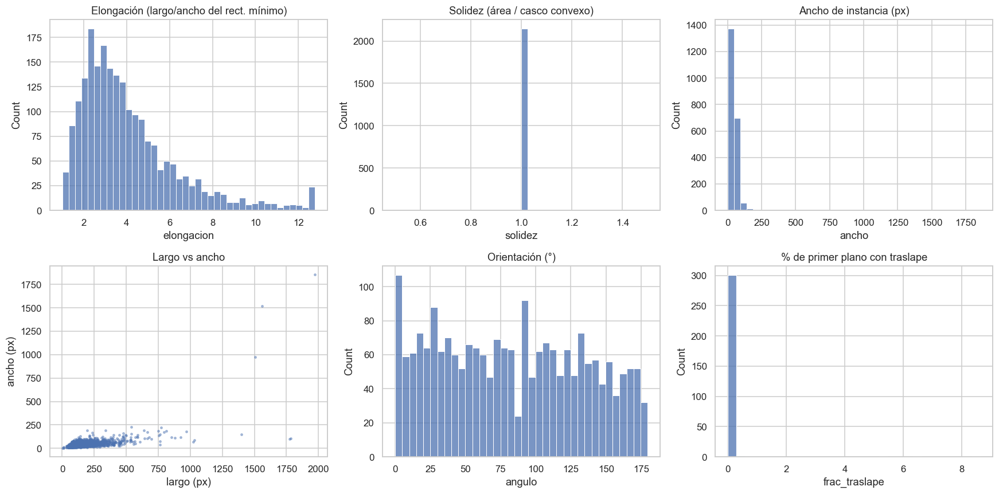

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(df_morf["elongacion"].clip(upper=df_morf["elongacion"].quantile(.99)), bins=40, ax=axes[0, 0])
axes[0, 0].set_title("Elongación (largo/ancho del rect. mínimo)")
sns.histplot(df_morf["solidez"], bins=40, ax=axes[0, 1]); axes[0, 1].set_title("Solidez (área / casco convexo)")
sns.histplot(df_morf["ancho"], bins=40, ax=axes[0, 2]); axes[0, 2].set_title("Ancho de instancia (px)")
axes[1, 0].scatter(df_morf["largo"], df_morf["ancho"], s=5, alpha=.4)
axes[1, 0].set(title="Largo vs ancho", xlabel="largo (px)", ylabel="ancho (px)")
sns.histplot(df_morf["angulo"] % 180, bins=36, ax=axes[1, 1]); axes[1, 1].set_title("Orientación (°)")
sns.histplot(df["frac_traslape"] * 100, bins=30, ax=axes[1, 2]); axes[1, 2].set_title("% de primer plano con traslape")
plt.tight_layout(); plt.savefig(OUT / "07_morfologia.png", bbox_inches="tight"); plt.show()

### 🔎 Observaciones — Morfología
- **Elongación** (largo/ancho): mediana 3.5, con la mayoría entre 2 y 6. Son tramos alargados, no miotubos completos (que serían mucho más largos). *La barra en ~12.7 es un artefacto del recorte al percentil 99 en la gráfica.*
- **Solidez = 1.00 en todos los casos**, como era de esperar: un rectángulo siempre es convexo. **Esta métrica no aporta información en este dataset.**
- **Ancho:** mediana ≈ 40 px (rango típico 28–57 px). Los 2–3 puntos con ancho > 900 px en "Largo vs ancho" son las **cajas gigantes erróneas**.
- **Orientación:** distribución aproximadamente uniforme en 0–180°, con picos en 0° y 90° (cajas alineadas a los ejes, típicas de la herramienta de anotación). **Rotaciones y volteos son aumentos válidos.**
- **Traslapes:** solo 14 imágenes tienen algún traslape, y apenas el 0.07 % del primer plano pertenece a más de una caja.

**Para qué sirve:**
- El **ancho** típico de los miotubos orienta el tamaño de parche / factor de *resize* (no reducir tanto que un miotubo quede de 1–2 px).
- **Orientación** uniforme → rotaciones/volteos son aumentos seguros.
- **Traslape** y diferencia entre `comp_conexas` (máscara) y `n_inst` (YOLO) → cuánto se pierde la identidad individual en la máscara semántica (pregunta guía sobre semántica vs. instancia).

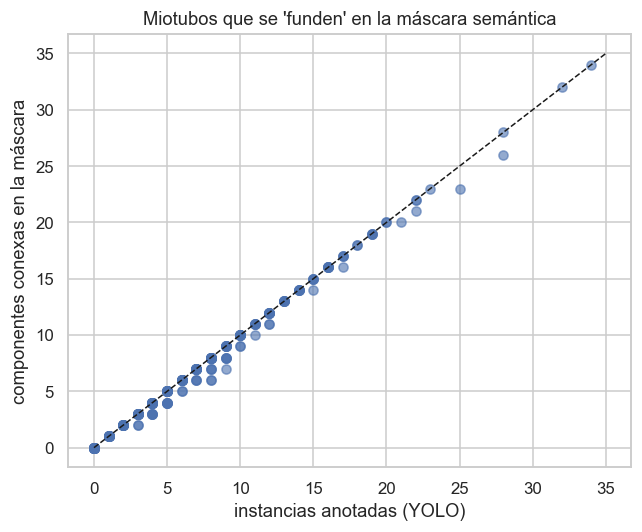

In [19]:
# Fusión de instancias en la máscara semántica: instancias YOLO vs componentes conexas de la máscara
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df["n_inst_yolo"], df["comp_conexas"], alpha=.6)
lim = np.nanmax([df["n_inst_yolo"].max(), df["comp_conexas"].max()]) + 1
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set(xlabel="instancias anotadas (YOLO)", ylabel="componentes conexas en la máscara",
       title="Miotubos que se 'funden' en la máscara semántica")
plt.tight_layout(); plt.savefig(OUT / "07_instancias_vs_componentes.png", bbox_inches="tight"); plt.show()

### 🔎 Observaciones — Instancias vs componentes conexas
- Casi todos los puntos caen sobre la diagonal. **Pocas cajas se fusionan** en la máscara semántica (como mucho 2–5 en las imágenes con más anotaciones).
- Ojo: esto **no** quiere decir que la formulación semántica baste para separar miotubos. Las cajas son segmentos, así que un miotubo ramificado aparece como varias componentes, y miotubos que se tocan no están anotados en su totalidad. Para la pregunta guía sobre semántica vs. instancia, la limitación real es **cómo está anotado el dataset**, no el traslape.

## 8. Inspección visual

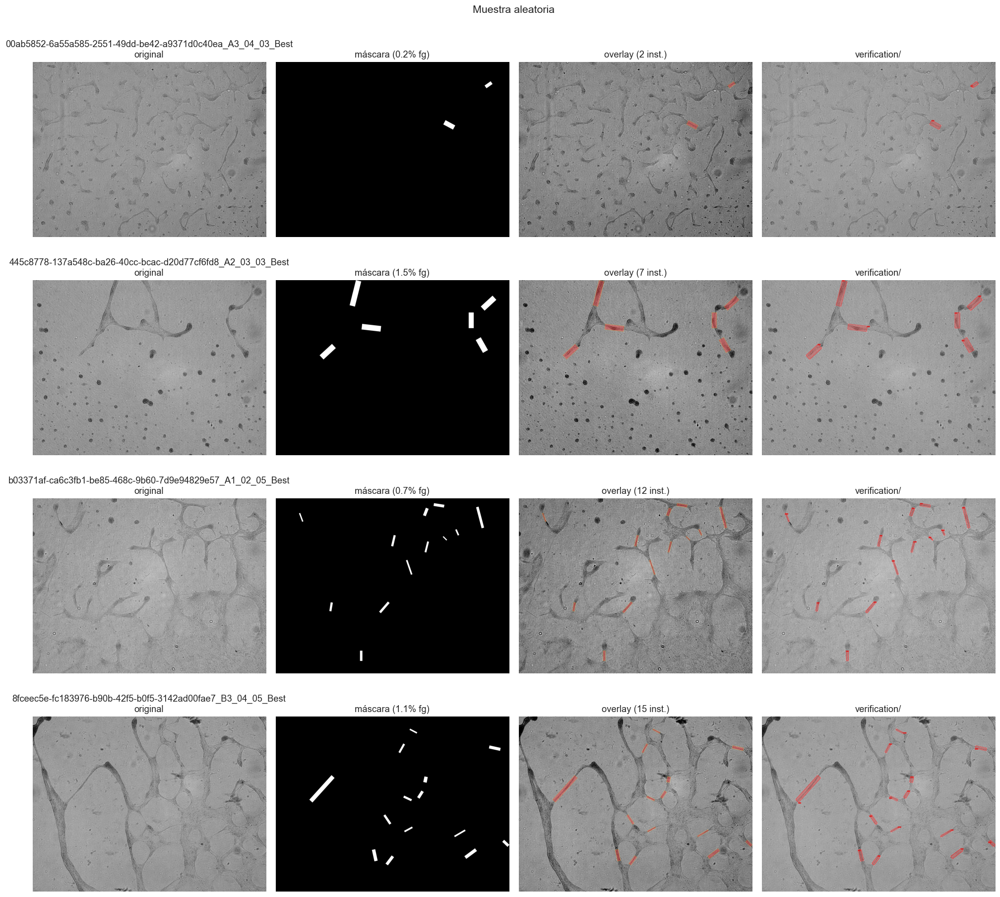

In [20]:
def norm_vis(a):
    # Estira percentiles 1-99 solo para visualizar (no se usa en entrenamiento)
    g = a_gris(a).astype(np.float32)
    lo, hi = np.percentile(g, [1, 99])
    return np.clip((g - lo) / (hi - lo + 1e-6), 0, 1)

def overlay(img, m, color=(1, 0.2, 0.2), alpha=.4):
    rgb = np.dstack([img] * 3)
    m = m > 0
    rgb[m] = (1 - alpha) * rgb[m] + alpha * np.array(color)
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    rgb = np.ascontiguousarray((rgb * 255).astype(np.uint8))
    cv2.drawContours(rgb, cnts, -1, (255, 255, 0), 1)
    return rgb

def panel(stems, titulo, archivo=None):
    n = len(stems)
    if n == 0:
        print("(sin imágenes para mostrar)"); return
    fig, axes = plt.subplots(n, 4, figsize=(18, 4.2 * n), squeeze=False)
    for i, s in enumerate(stems):
        a = leer(img_files[s]); v = norm_vis(a)
        m = leer(mask_files[s]) if s in mask_files else np.zeros(v.shape, np.uint8)
        m = m[..., 0] if m.ndim == 3 else m
        axes[i, 0].imshow(a_gris(a), cmap="gray"); axes[i, 0].set_title(f"{s}\noriginal")
        axes[i, 1].imshow(m > 0, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title(f"máscara ({df.loc[s,'frac_fg']:.1%} fg)")
        axes[i, 2].imshow(overlay(v, m)); axes[i, 2].set_title(f"overlay ({int(df.loc[s,'n_inst_yolo']) if pd.notna(df.loc[s,'n_inst_yolo']) else '?'} inst.)")
        if s in ver_files:
            axes[i, 3].imshow(leer(ver_files[s])); axes[i, 3].set_title("verification/")
        else:
            axes[i, 3].text(.5, .5, "sin overlay", ha="center")
        for ax in axes[i]:
            ax.axis("off")
    fig.suptitle(titulo, fontsize=14, y=1.0)
    plt.tight_layout()
    if archivo:
        plt.savefig(OUT / archivo, bbox_inches="tight")
    plt.show()

panel(random.sample(STEMS, min(4, len(STEMS))), "Muestra aleatoria", "08_muestra.png")

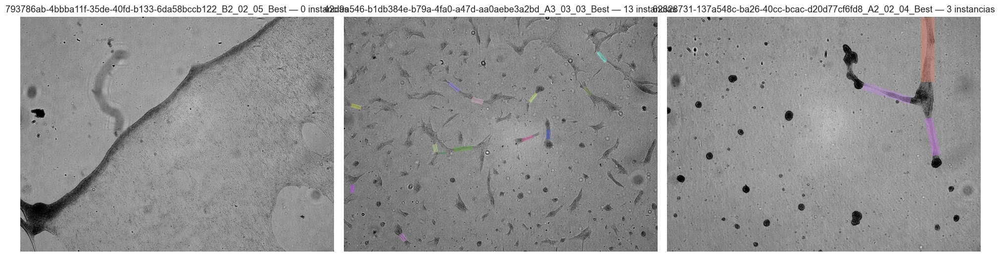

In [21]:
# Instancias individuales coloreadas (vista tipo segmentación por instancia)
def panel_instancias(stems):
    fig, axes = plt.subplots(1, len(stems), figsize=(6 * len(stems), 5), squeeze=False)
    rng = np.random.default_rng(SEED)
    for ax, s in zip(axes[0], stems):
        v = norm_vis(leer(img_files[s])); H, W = v.shape
        rgb = np.dstack([v] * 3).copy()
        for _, pts in YOLO.get(s, []):
            if len(pts) < 3: continue
            c = rng.uniform(.2, 1, 3)
            inst = np.zeros((H, W), np.uint8)
            cv2.fillPoly(inst, [np.round(pts * [W, H]).astype(np.int32)], 1)
            rgb[inst > 0] = .5 * rgb[inst > 0] + .5 * c
        ax.imshow(rgb); ax.set_title(f"{s} — {len(YOLO.get(s, []))} instancias"); ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT / "08_instancias.png", bbox_inches="tight"); plt.show()

panel_instancias(random.sample(STEMS, min(3, len(STEMS))))

### 🔎 Observaciones — Inspección visual
- **Muestra aleatoria e instancias:** los overlays propios coinciden con `verification/`. La conversión de etiquetas es correcta.
- Se confirma visualmente que las anotaciones son **rectángulos sobre tramos rectos** de miotubos, y que **muchos miotubos o ramas visibles quedan sin anotar** (sobre todo en imágenes densas como `b03371af-...` y `8fceec5e-...`).
- Las imágenes muestran **muchos artefactos oscuros y redondos** (células sin fusionar, restos, burbujas) con un contraste parecido al de los miotubos. Son una fuente probable de falsos positivos en la línea base por umbral.

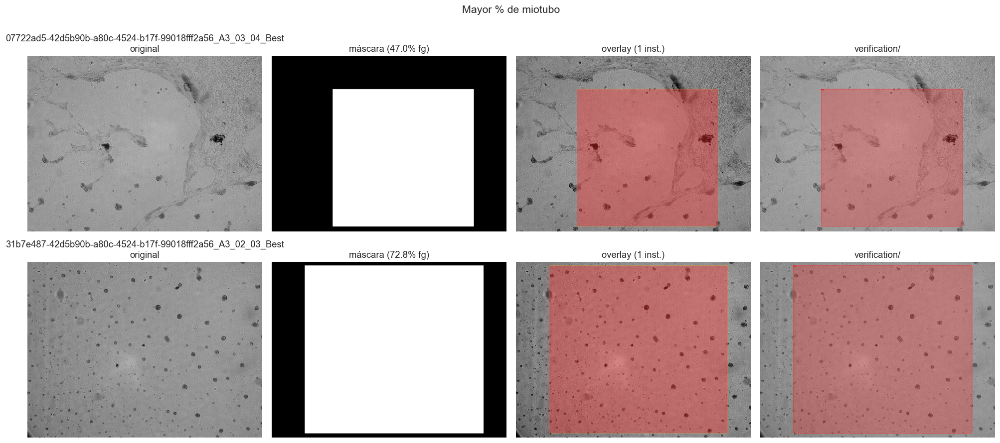

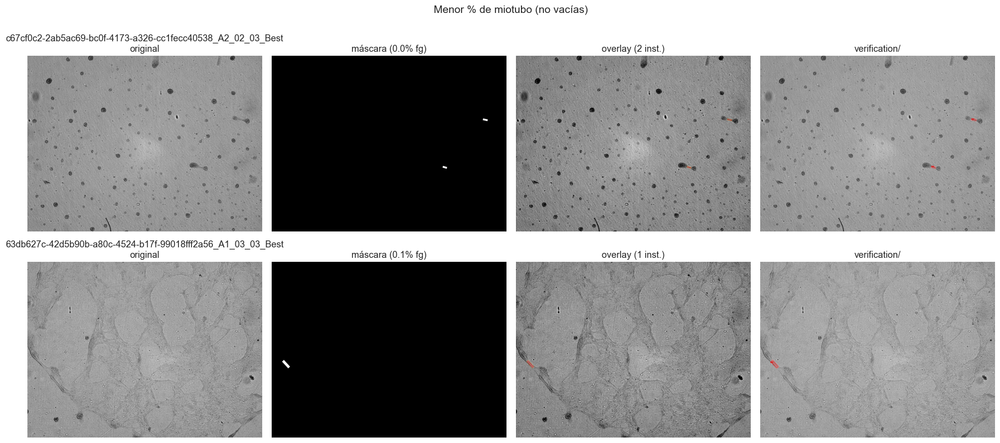

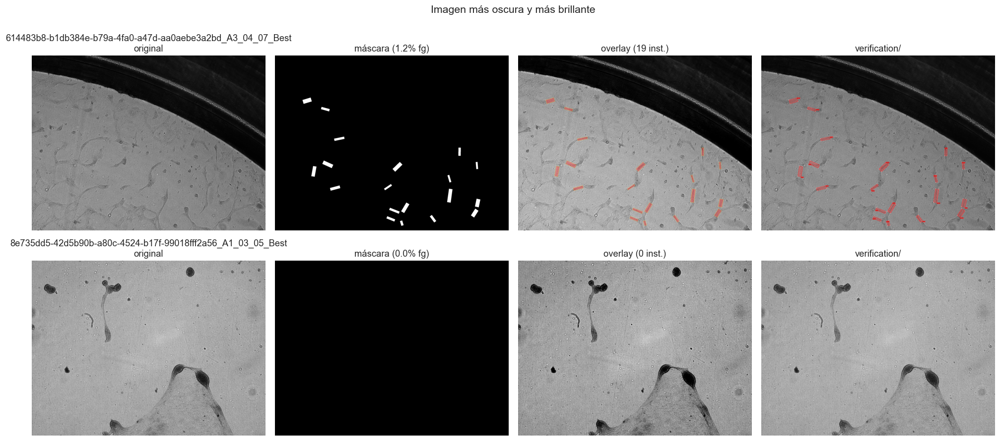

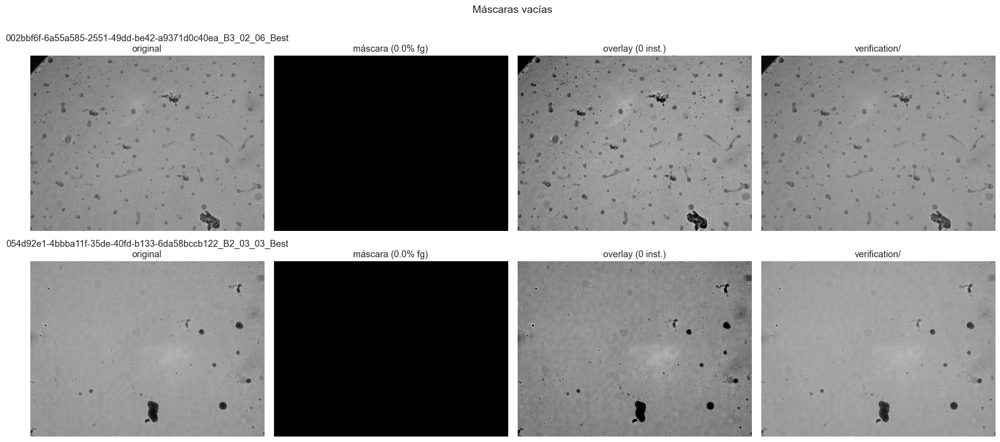

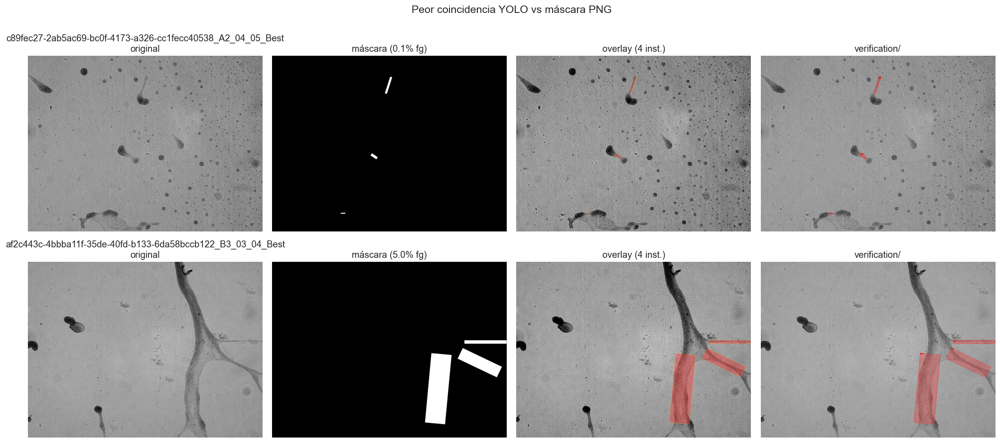

In [22]:
# Casos extremos: útiles para anticipar dónde fallará el modelo
orden_fg = df["frac_fg"].dropna().sort_values()
panel(list(orden_fg.index[-2:]), "Mayor % de miotubo", "08_mas_fg.png")
panel(list(orden_fg[orden_fg > 0].index[:2]), "Menor % de miotubo (no vacías)", "08_menos_fg.png")
panel(list(df["media"].sort_values().index[:1]) + list(df["media"].sort_values().index[-1:]),
      "Imagen más oscura y más brillante", "08_iluminacion.png")
vacias = list(df[df["frac_fg"] == 0].index[:2])
if vacias:
    panel(vacias, "Máscaras vacías", "08_vacias.png")
if len(malos):
    panel(list(malos.index[:2]), "Peor coincidencia YOLO vs máscara PNG", "08_inconsistentes.png")

### 🔎 Observaciones — Casos extremos
- **Mayor % de miotubo** (`07722ad5-...` 47 % y `31b7e487-...` 72.8 %): **cajas gigantes mal anotadas**. En la segunda no hay ningún miotubo visible bajo la caja. → **Excluir estas instancias o imágenes** y documentarlo.
- **Imagen más oscura** (`614483b8-...`): tiene el **borde negro del pozo** en una esquina. Es un caso que puede confundir al modelo.
- **Imagen más brillante** (`8e735dd5-...`): **máscara vacía con miotubos claramente visibles**.
- **Máscaras vacías:** `002bbf6f-...` muestra células alargadas pequeñas (dudoso) y `054d92e1-...` parece un negativo real. **Las 34 vacías mezclan negativos reales con imágenes sin anotar** y conviene revisarlas una por una antes de decidir.
- **Peor coincidencia YOLO vs máscara:** visualmente coinciden. La diferencia está en los bordes de cajas delgadas (ver sección 6).

## 9. Indicios de grupos y posibles duplicados (riesgo de *data leakage*)

El documento advierte que imágenes de la misma placa/pozo/día deben quedar en la misma partición. Aquí se busca:
1. **Patrones en los nombres de archivo** (prefijos, fechas, pozos) que sugieran grupos.
2. **Imágenes casi duplicadas** mediante un hash perceptual (dHash).

In [23]:
# 9.1 Patrones en nombres
print("Ejemplos de nombres:", STEMS[:10])

def tokens(s):
    return [t for t in re.split(r"[_\-\s\.]+", s) if t]

n_tok = Counter(len(tokens(s)) for s in STEMS)
print("Nº de tokens por nombre:", dict(n_tok))

# Prefijo antes del último separador como posible 'grupo'
def prefijo(s):
    t = re.split(r"[_\-\s]+", s)
    return "_".join(t[:-1]) if len(t) > 1 else re.sub(r"\d+$", "", s)

df["grupo_nombre"] = [prefijo(s) for s in df.index]
g = df["grupo_nombre"].value_counts()
print(f"Grupos candidatos por prefijo: {len(g)} (tamaño medio {g.mean():.1f})")
display(g.head(20).to_frame("n_imágenes"))

# Columnas por posición de token (útil para detectar placa/pozo/fecha manualmente)
max_t = max(n_tok)
tok_df = pd.DataFrame([tokens(s) + [None] * (max_t - len(tokens(s))) for s in STEMS],
                      index=STEMS, columns=[f"tok{i}" for i in range(max_t)])
print("Valores únicos por posición de token:")
display(tok_df.nunique().to_frame("n_únicos").T)

Ejemplos de nombres: ['002bbf6f-6a55a585-2551-49dd-be42-a9371d0c40ea_B3_02_06_Best', '00538475-f23e64e2-8f62-4391-bd64-e8ecbaafc9be_B2_02_06_Best', '0062917b-195893df-aa40-4944-8592-2fa62f94d608_B2_02_03_Best', '00ab5852-6a55a585-2551-49dd-be42-a9371d0c40ea_A3_04_03_Best', '0108f6b1-cell28', '015a70b9-35f892c1-da41-4a26-afbf-cb846cdf7436_A2_03_05_Best', '02fd00da-4b2b8615-75d4-4b2e-bccd-5731cc9b8ffc_A2_03_06_Best', '047e5b0e-1eba6db2-8449-4040-b93d-3a69b30070ff_A3_05_05_Best', '054d92e1-4bbba11f-35de-40fd-b133-6da58bccb122_B2_03_03_Best', '05e702c6-cell17']
Nº de tokens por nombre: {10: 254, 2: 51, 3: 1}
Grupos candidatos por prefijo: 306 (tamaño medio 1.0)


,n_imágenes
grupo_nombre,
002bbf6f_6a55a585_2551_49dd_be42_a9371d0c40ea_B3_02_06,1
a74fc0a0_9e75d0f9_bb79_4db6_8f0a_a01cdb15d2d0_A3_03_04,1
aac6195b_7ddb4822_a089_40ee_9afb_a8b0117d3d32_A2_02_06,1
a98d21c7_daf8b91e_da39_4130_ac30_d158a92666fd_B2_04_04,1
a82fb0ac_42d5b90b_a80c_4524_b17f_99018fff2a56_B2_02_06,1
a7ef3fdf_35f892c1_da41_4a26_afbf_cb846cdf7436_A2_02_04,1
a7e7b263_4b2b8615_75d4_4b2e_bccd_5731cc9b8ffc_A3_03_05,1
a7dc2363_d9035cfd_e2e1_45bc_accc_f717d8f8a6e6_A3_02_04,1
a7b53b95,1


Valores únicos por posición de token:


,tok0,tok1,tok2,tok3,tok4,tok5,tok6,tok7,tok8,tok9
n_únicos,306,73,31,30,30,30,6,5,6,1


### 🔎 Observaciones — Nombres de archivo
- El "prefijo antes del último separador" no sirve para agrupar: da 306 grupos de 1, porque el primer token es un hash único por archivo (`tok0` = 306 valores únicos).
- Estructura del nombre `<hash8>-<UUID>_<pozo>_<f>_<c>_Best`:
  - el **UUID** (`tok1`–`tok5`) tiene ~30 valores. Puede ser el lote, la placa o la sesión de carga;
  - `tok6` tiene **6 valores** (A1–A3, B1–B3): parece el **pozo**;
  - `tok7` y `tok8` (5–6 valores) parecen la **posición o campo** dentro del pozo;
  - `tok9` es siempre `Best`.
- **Si se confirma con quien generó los datos que el UUID es la placa o el experimento, esa debe ser la variable de agrupación** para la partición.

dHash:   0%|          | 0/306 [00:00<?, ?it/s]

Pares de imágenes casi duplicadas (Hamming ≤ 6): 117


,img_a,img_b,hamming
88,89612d35-cell2,f2c7a99a-cell2,0
21,141653d6-cell9,ef706849-cell9,0
42,2b70bcae-cell1,922a7a35-cell1,0
29,196ffab0-cell38,634a6598-cell38,0
84,7b06026e-d58ccaa3-12bd-4a58-ac75-6c90482cc329_...,87d4c6f1-eebfb204-b362-4bb2-8684-6dc0c6a18f99_...,0
18,0f0704fc-cell8,898190c6-cell8,0
115,e0ba335d-eebfb204-b362-4bb2-8684-6dc0c6a18f99_...,ef592a8c-eebfb204-b362-4bb2-8684-6dc0c6a18f99_...,0
56,429ecf67-cell21,c264d669-cell21,0
6,09195104-cell21,c264d669-cell21,0
5,09195104-cell21,429ecf67-cell21,0


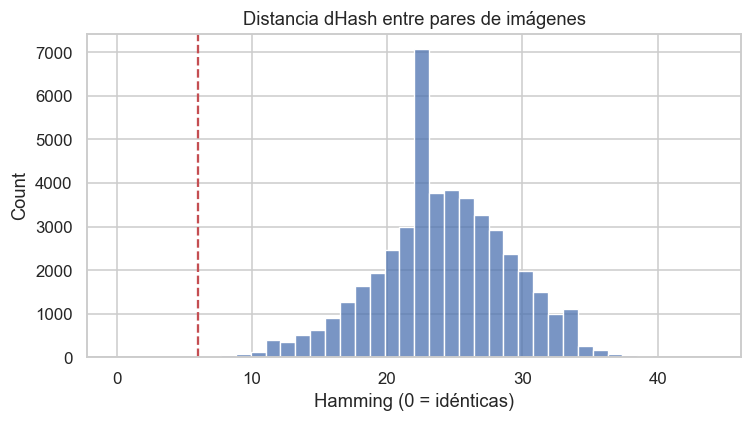

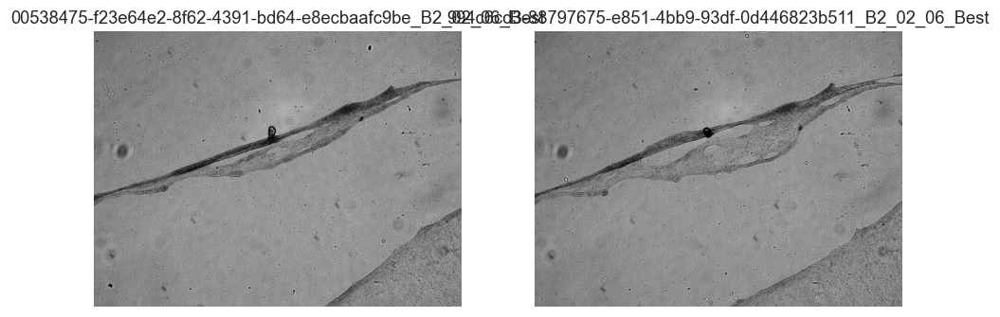

In [24]:
# 9.2 Casi-duplicados con dHash (64 bits)
def dhash(a, n=8):
    g = cv2.resize(norm_vis(a), (n + 1, n), interpolation=cv2.INTER_AREA)
    return (g[:, 1:] > g[:, :-1]).flatten()

hashes = np.array([dhash(leer(img_files[s])) for s in tqdm(STEMS, desc="dHash")])
D = (hashes[:, None, :] != hashes[None, :, :]).sum(-1)   # distancia de Hamming
np.fill_diagonal(D, 99)

UMBRAL = 6   # <=6 de 64 bits distintos → muy parecidas
pares = [(STEMS[i], STEMS[j], int(D[i, j])) for i in range(len(STEMS)) for j in range(i + 1, len(STEMS)) if D[i, j] <= UMBRAL]
print(f"Pares de imágenes casi duplicadas (Hamming ≤ {UMBRAL}): {len(pares)}")
display(pd.DataFrame(pares, columns=["img_a", "img_b", "hamming"]).sort_values("hamming").head(20))

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(D[np.triu_indices(len(STEMS), 1)], bins=40, ax=ax)
ax.axvline(UMBRAL, color="r", ls="--"); ax.set(title="Distancia dHash entre pares de imágenes", xlabel="Hamming (0 = idénticas)")
plt.tight_layout(); plt.savefig(OUT / "09_duplicados.png", bbox_inches="tight"); plt.show()

if pares:
    a, b, _ = pares[0]
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(norm_vis(leer(img_files[a])), cmap="gray"); axes[0].set_title(a)
    axes[1].imshow(norm_vis(leer(img_files[b])), cmap="gray"); axes[1].set_title(b)
    for ax in axes: ax.axis("off")
    plt.show()

### 🔎 Observaciones — Duplicados (riesgo crítico de *data leakage*)
- Hay **117 pares con Hamming ≤ 6**, y muchos con **Hamming = 0: son la misma imagen subida más de una vez** con un hash distinto. Por ejemplo:
  - `89612d35-cell2` = `f2c7a99a-cell2`;
  - `cell21` aparece 3 veces;
  - `00538475-f23e64e2-..._B2_02_06_Best` y `...-88797675-..._B2_02_06_Best` son la misma imagen **con UUID distinto** (comparten pozo y posición `B2_02_06`).
- Por lo tanto **ni el hash ni el UUID identifican de forma única una imagen original**. El número real de imágenes distintas es **menor a 306**.
- El histograma de distancias muestra un grupo separado cerca de 0 (duplicados) y el resto con distancias > 15. El umbral de 6 parece razonable, pero los pares con Hamming de 3–6 se deben revisar visualmente.
- **Acciones antes de particionar:**
  1. formar grupos uniendo los pares duplicados (componentes conexas del grafo de pares) y añadir el mismo sufijo (`cellNN` o `pozo_f_c`) como criterio extra;
  2. comprobar si las copias tienen **la misma anotación**. Si difieren, hay inconsistencia entre anotadores y hay que documentarla;
  3. quedarse con una copia por grupo, o mantener el grupo completo en la misma partición (`GroupShuffleSplit` / `GroupKFold`).

## 10. Resumen y exportación

In [25]:
resumen = {
    "n_imagenes": len(STEMS),
    "resoluciones_distintas": int(df.groupby(["alto", "ancho"]).ngroups),
    "dtypes": sorted(df["dtype"].unique().tolist()),
    "canales": sorted(df["canales"].unique().tolist()),
    "mascaras_vacias": int((df["frac_fg"] == 0).sum()),
    "pct_px_miotubo_global": round(100 * frac, 3),
    "pos_weight_sugerido": round((1 - frac) / max(frac, 1e-9), 2),
    "instancias_totales": int(len(df_inst)),
    "instancias_por_imagen_mediana": float(df["n_inst_yolo"].median()),
    "poligonos_con_problemas": int(len(df_prob)),
    "imgs_iou_yolo_mask_<0.95": int((df["iou_yolo_vs_mask"] < 0.95).sum()),
    "imgs_con_traslape": int((df["frac_traslape"] > 0).sum()),
    "ancho_mediano_miotubo_px": round(float(df_morf["ancho"].median()), 1) if len(df_morf) else None,
    "grupos_por_prefijo": int(df["grupo_nombre"].nunique()),
    "pares_casi_duplicados": len(pares),
}
for k, v in resumen.items():
    print(f"{k:32s} {v}")

df.to_csv(OUT / "eda_por_imagen.csv")
df_inst.to_csv(OUT / "eda_por_instancia_yolo.csv", index=False)
df_morf.to_csv(OUT / "eda_morfologia.csv", index=False)
df_prob.to_csv(OUT / "eda_problemas_labels.csv", index=False)
with open(OUT / "eda_resumen.json", "w") as f:
    json.dump(resumen, f, indent=2, default=str)
print("\nArchivos guardados en:", OUT)

n_imagenes                       306
resoluciones_distintas           1
dtypes                           ['uint8']
canales                          [1]
mascaras_vacias                  34
pct_px_miotubo_global            1.759
pos_weight_sugerido              55.84
instancias_totales               2148
instancias_por_imagen_mediana    6.0
poligonos_con_problemas          30
imgs_iou_yolo_mask_<0.95         51
imgs_con_traslape                14
ancho_mediano_miotubo_px         40.5
grupos_por_prefijo               306
pares_casi_duplicados            117

Archivos guardados en: \content\eda_outputs


## Conclusiones para las siguientes etapas

| Hallazgo | Implicación para preprocesamiento / entrenamiento |
|---|---|
| **Resolución:** las 306 imágenes son 2592×1944 | No hay que homologar tamaños. Por memoria: *resize* a ½ (1296×972) o parches (p. ej. 512×512) a resolución completa con reconstrucción por *tiling*. |
| **dtype / canales:** uint8, 1 canal (escala de grises real) | Entrada de 1 canal. Normalizar ÷255 y luego z-score con media/std **solo de train**. Si se usa un encoder preentrenado en ImageNet, replicar el canal ×3. |
| **% miotubo:** 1.76 % global (≈ 56:1), mediana 0.86 % por imagen | BCE + Dice (o Focal + Dice). `pos_weight` ≈ 56 es el valor teórico; empezar más bajo (10–20) para no inflar falsos positivos. Nunca usar *accuracy*. |
| **Máscaras vacías:** 34 (11 %), y varias tienen miotubos visibles | No tratarlas como negativos confiables: excluirlas del entrenamiento o revisarlas una por una. Documentar la decisión. |
| **Anotación = rectángulos de 4 vértices que cubren segmentos de miotubo, no el contorno completo** | Es la limitación principal del dataset. Hay muchos píxeles de miotubo etiquetados como fondo, así que el modelo será penalizado por segmentar miotubos reales y la precisión/IoU subestimarán el desempeño. Hay que discutirlo en el reporte y en el análisis de errores. |
| **Etiquetas erróneas:** 2 cajas gigantes (47 % y 73 % de la imagen, lote `42d5b90b`), 30 polígonos fuera de [0,1] y ~22 casi sin área | Excluir o corregir (con *clip* a [0,1]) **y documentarlo** (sección 6 del documento del proyecto). |
| **YOLO ≠ máscara en 51 imágenes (IoU < 0.95) y COCO con 30 instancias menos** | Usar `masks_png` como Y (lo recomendado) y reportar que COCO descarta los polígonos fuera de rango. |
| **Iluminación:** homogénea (±4 % centro vs. bordes); ~20 imágenes con el borde oscuro del pozo | Una corrección de fondo/CLAHE es opcional; compararla en validación. Aumentos de brillo/contraste moderados. |
| **Ancho típico anotado:** mediana ≈ 40 px | Con *resize* ×½ quedan ~20 px (seguro). No bajar de ×¼ (~10 px). |
| **Traslapes:** casi nulos (0.07 % del primer plano) | La máscara semántica casi no fusiona anotaciones. Pero una "instancia" es un **segmento**, no un miotubo completo, así que la formulación por instancia no representa miotubos individuales. |
| **Orientación:** ~uniforme en 0–180° | Rotaciones de 90° y volteos horizontales/verticales son aumentos seguros. |
| **Duplicados:** 117 pares casi idénticos (muchos con Hamming = 0), incluso con UUID distinto | **Riesgo alto de *data leakage*.** Agrupar duplicados (unión de pares con Hamming ≤ 6, más el mismo sufijo de nombre) y particionar con `GroupShuffleSplit`. Antes, comprobar si las copias tienen la misma anotación. |